# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [2]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data? _No_

In [3]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

In [4]:
# Q1: your code here
corr = np.corrcoef(X.T)
pairs = [(abs(corr[i, j]), corr[i, j], iris.feature_names[i], iris.feature_names[j])
         for i in range(4) for j in range(i + 1, 4)]

print("Most correlated:", max(pairs))
print("Least correlated:", min(pairs, key=lambda p: p[1]))

print("np.cov(X.T) shape:", np.cov(X.T).shape)
print("np.cov(X) shape:", np.cov(X).shape)

Most correlated: (np.float64(0.9628654314027958), np.float64(0.9628654314027958), 'petal length (cm)', 'petal width (cm)')
Least correlated: (np.float64(0.42844010433054014), np.float64(-0.42844010433054014), 'sepal width (cm)', 'petal length (cm)')
np.cov(X.T) shape: (4, 4)
np.cov(X) shape: (150, 150)


## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [6]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. Show the characteristic equation is $(1-\lambda)^2-r^2=0$, so $\lambda=1\pm r$.
2. Using the value of $r$ printed above, write both eigenvalues. (Hint: r is negative.)
3. Explained variance of PC1 = $\lambda_1/(\lambda_1+\lambda_2)$ = ___ %
4. Eigenvector for the larger eigenvalue (roughly ±0.71, ∓0.71 pattern): ___

In [7]:
# Use your hand answers to fill in, then verify with np.linalg.eigh(C)
# det(C - λI) = |1-λ   r  |
#               | r   1-λ |
# (1 - λ)**2 - r**2 = 0
# λ = 1 ± r

r = C[0, 1]
eigenvalues = 1 + abs(r), 1 - abs(r)
print("Eigenvalues:", eigenvalues)

explained_variance = eigenvalues[0] / sum(eigenvalues) * 100
print("Explained variance of PC1:", round(explained_variance, 2), "%")

eigenvectors = np.linalg.eigh(C)[1]
pc1 = eigenvectors[:, np.argmax(np.linalg.eigvalsh(C))]
print("Eigenvector for PC1:", pc1)

Eigenvalues: (np.float64(1.613006033832888), np.float64(0.3869939661671119))
Explained variance of PC1: 80.65 %
Eigenvector for PC1: [-0.7071  0.7071]


### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? 1 number per student. Run `Z[:, 0]` after finishing the verification to see them.

## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [8]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: <50% / 50-80% / >95%. Then scale and compare below. **Deliberate error:** the unscaled result is misleading. Explain why in one line.

Ans: The unscaled PCA is misleading because features with large numerical scales and variances dominate the principal components; StandardScaler puts all features on a comparable scale before PCA.

WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


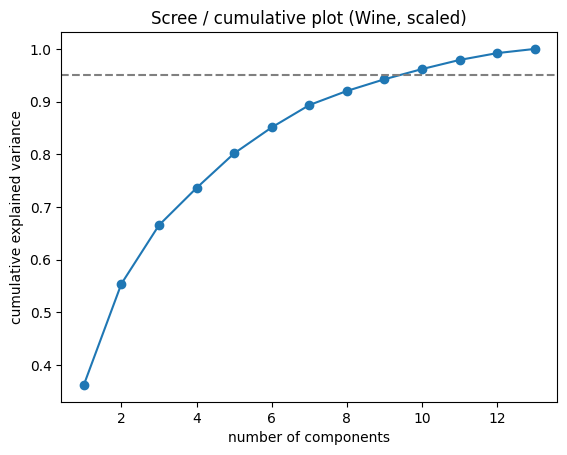

In [9]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine?
2. In the lecture's PCA steps, which step did the unscaled run skip?

Ans: Skipped step- Feature standardization (scaling) before computing PCA. The unscaled run used the original features, allowing high-variance features to dominate the principal components.

In [10]:
# your code here
print(np.argmax(cum >= 0.95) + 1)

10


# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [11]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: ~5 / ~15 / ~30 / ~55. And what will KNN accuracy look like with only 10 components?

Ans: 1. Guess for 90% variance: ~30 components. KNN accuracy with only 10 components: It will likely be reasonably high, but lower than using all 64 components because dimensionality reduction discards some information.

### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796?
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? Why might that be? (Think: what do tree splits do to axes?)

In [12]:
# Q1-Q3: your code here
results = []

for k in [2, 5, 10, 20, 30, 40, 64]:
    pca_k = PCA(n_components=k).fit(Xtr)
    Xtr_k = pca_k.transform(Xtr)
    Xte_k = pca_k.transform(Xte)

    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(Xtr_k, yd_train)
    knn_acc = knn.score(Xte_k, yd_test)

    tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
    tree.fit(Xtr_k, yd_train)
    tree_acc = tree.score(Xte_k, yd_test)

    results.append((k, knn_acc, tree_acc))

print("k | KNN accuracy | Tree accuracy")
for k, knn_acc, tree_acc in results:
    print(f"{k:2d} | {knn_acc:.4f}       | {tree_acc:.4f}")

print("\nK values within 0.5 percentage points:")
print([k for k, acc, _ in results if acc >= 0.9796 - 0.005])

print("\nTree comparison with raw-pixel baseline (0.8815):")
for k, _, tree_acc in results:
    if tree_acc > 0.8815:
        status = "improves"
    elif tree_acc < 0.8815:
        status = "gets worse"
    else:
        status = "stays the same"
    print(f"k={k}: {tree_acc:.4f} -> {status}")

k | KNN accuracy | Tree accuracy
 2 | 0.5648       | 0.4944
 5 | 0.8759       | 0.7759
10 | 0.9426       | 0.8241
20 | 0.9722       | 0.8222
30 | 0.9778       | 0.8185
40 | 0.9759       | 0.8222
64 | 0.9796       | 0.8074

K values within 0.5 percentage points:
[30, 40, 64]

Tree comparison with raw-pixel baseline (0.8815):
k=2: 0.4944 -> gets worse
k=5: 0.7759 -> gets worse
k=10: 0.8241 -> gets worse
k=20: 0.8222 -> gets worse
k=30: 0.8185 -> gets worse
k=40: 0.8222 -> gets worse
k=64: 0.8074 -> gets worse


### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

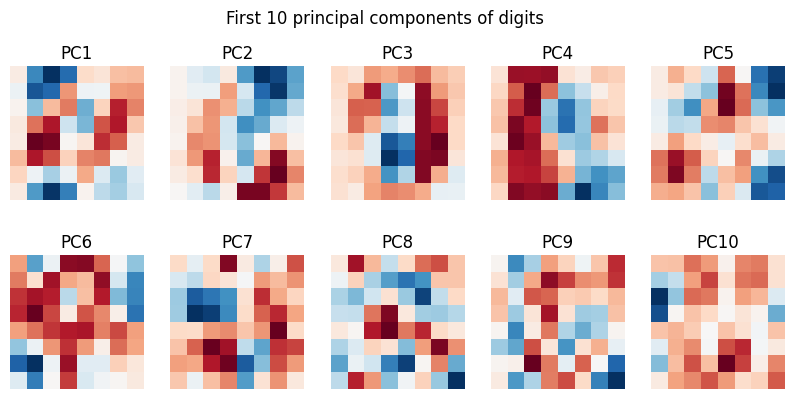

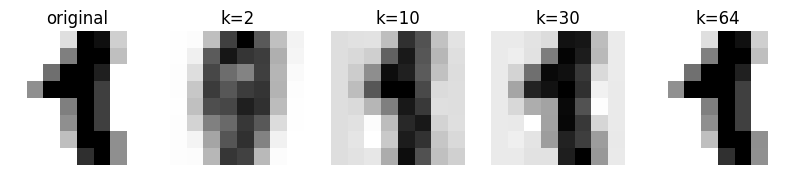

In [14]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

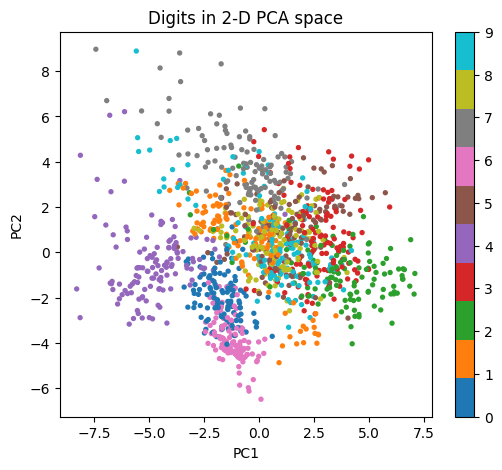

In [15]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(2).fit(Xtr).transform(Xtr)
plt.figure(figsize=(6, 5)); sc_ = plt.scatter(Z2[:, 0], Z2[:, 1], c=yd_train, cmap='tab10', s=8)
plt.colorbar(sc_); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Digits in 2-D PCA space'); plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?

Ans: This is wrong because of data leakage. StandardScaler and PCA are fitted on the entire dataset, including test rows, so information from the test set influences preprocessing. Even without using test labels, this contaminates the evaluation and can make accuracy misleading.

In [16]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [13]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns. (a) What is the maximum number of non-zero principal components? (b) Will 2 components capture >90% of variance?

Ans: (a) Maximum number of non-zero principal components: 5.

(b) Not necessarily. Two components are unlikely to capture more than 90% of the variance, but the exact answer requires calculating the explained variance ratios.

### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest?
4. Print the 5 words with the largest absolute weight on PC1 and PC2.

Explained variance ratios: [0.2642 0.2088]
Sum: 0.4730751133209796


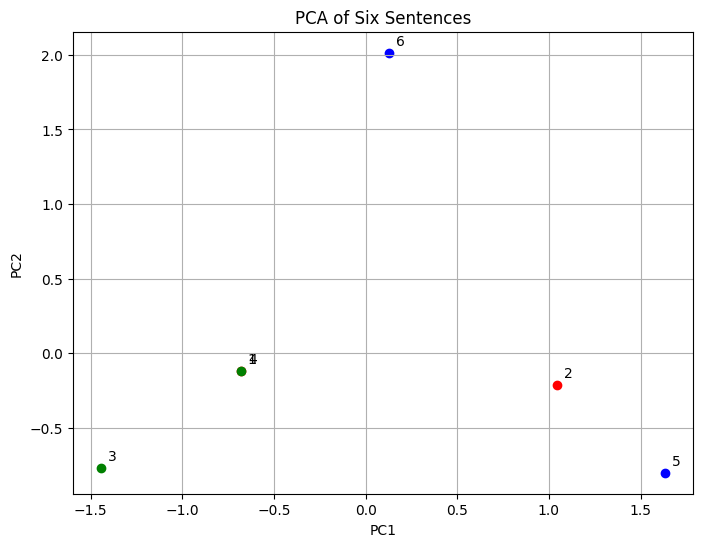

Closest pair: Sentence 1 and Sentence 4
the cricket team won the match
add salt and simmer the curry
Distance: 0.0

Same-topic sentences may cluster together, but this is not guaranteed.

Top 5 words on PC1:
a 0.3946
and -0.3133
the -0.3133
processor 0.2405
new 0.2405

Top 5 words on PC2:
all 0.3758
laptop 0.3758
day 0.3758
lasts 0.3758
battery 0.3758


In [17]:
# Q1-Q4: your code here
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations

pca_text = PCA(n_components=2)
Z_text = pca_text.fit_transform(X_text)

print("Explained variance ratios:", pca_text.explained_variance_ratio_)
print("Sum:", pca_text.explained_variance_ratio_.sum())

label_colors = {'sports': 'red', 'cooking': 'green', 'tech': 'blue'}

plt.figure(figsize=(8, 6))
for i, (x, y) in enumerate(Z_text):
    plt.scatter(x, y, color=label_colors[labels[i]])
    plt.annotate(str(i + 1), (x, y), xytext=(5, 5),
                 textcoords='offset points')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Six Sentences')
plt.grid(True)
plt.show()

pairs = [(np.linalg.norm(Z_text[i] - Z_text[j]), i, j)
         for i, j in combinations(range(len(sentences)), 2)]

distance, i, j = min(pairs)
print(f"Closest pair: Sentence {i+1} and Sentence {j+1}")
print(sentences[i])
print(sentences[j])
print("Distance:", round(distance, 4))

print("\nSame-topic sentences may cluster together, but this is not guaranteed.")

for pc in range(2):
    indices = np.argsort(np.abs(pca_text.components_[pc]))[::-1][:5]
    print(f"\nTop 5 words on PC{pc+1}:")
    for idx in indices:
        print(vocab[idx], round(pca_text.components_[pc, idx], 4))

## Part 6: Reflection (write 2–3 lines each)
1. In your own words: what does PCA keep and what does it throw away?
2. Why must we standardize before PCA? Give the Wine evidence.
3. Digits: pick the k you would deploy and justify (accuracy vs. size).
4. PCA helped KNN but not the tree. What does this say about when to use PCA?
5. PCA is **unsupervised**; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)
6. **Capstone link (Milestone, Week 9):** will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.

##Answers
1. PCA keeps the principal components that capture the most variance in the data and discards components with less variance. Some discarded information may be noise, but it can also contain useful information.

2. Standardization puts features on comparable scales so features with large numerical values do not dominate PCA. In the Wine dataset, comparing PC1's explained variance before and after scaling shows how strongly feature scales affect the results.

3. I would start with 30 components out of the original 64, provided its KNN accuracy remains close to the full-feature baseline. This reduces dimensionality while aiming to preserve classification performance.

4. PCA can help KNN by reducing noise and dimensionality, improving distance calculations. Decision trees use axis-aligned splits, which may become less effective on PCA-transformed features.

5. PCA ignores class labels and may discard low-variance features that are important for classification. LDA addresses this limitation by using class labels to find directions that separate classes.

6. I would evaluate PCA as an optional step in my Student Academic Risk Intelligence System and compare it against the original features. I would include it only if validation results show improved performance or efficiency without significantly reducing interpretability.

*Submit this notebook to GitHub under `labs/week9_pca/`.*